# Learning-Curve Calculator: H&R Block (HRB)

Fits **Cost(N) = Cost(1) · N^-b** to a public company's annual unit cost against its cumulative units, using only free public data:

* **Cost**: the 10-K cost-of-revenues line from SEC EDGAR XBRL `companyfacts` (data.sec.gov), one value per fiscal year, latest restated figure.
* **Units**: tax returns prepared (assisted + DIY), read from each 10-K's text. Every figure carries its exact quote, section and printed page, and is re-checked against the cached filing below.
* **Inflation**: CPI-U (`CPIAUCSL`) from the FRED public CSV, no key.

Learning rate = 1 − 2^−b: the share by which unit cost falls each time cumulative volume doubles.

**Run it:** set `SEC_USER_AGENT` in your environment (a descriptive string with contact info, as the SEC asks) only if `cache/` is missing a file; everything used here is cached in `learning-curve/cache/`, so a fresh clone runs offline. No paid API, no key.

Change `TICKER` below to run another company. The cost side is automatic; the units side needs a `units_<TICKER>.json` with quotes (units are not tagged in XBRL, so someone has to read the filings).

In [1]:
TICKER = "HRB"          # <- change me
WINDOW_START_FY = None  # None = first year in units_<TICKER>.json

In [2]:
import os, re, json, gzip, time, math, datetime as dt
from pathlib import Path
import numpy as np
import requests
from bs4 import BeautifulSoup
import matplotlib
import matplotlib.pyplot as plt

HERE = Path.cwd() if (Path.cwd() / "units_HRB.json").exists() else Path.cwd() / "learning-curve"
CACHE = HERE / "cache"
(CACHE / "10k").mkdir(parents=True, exist_ok=True)

def _ua():
    ua = os.environ.get("SEC_USER_AGENT", "").strip()
    if not ua:
        raise RuntimeError("Not cached and SEC_USER_AGENT is not set. Export a descriptive User-Agent, e.g. 'Name project contact@example.com'.")
    return ua

def cached(path, url, sec=True, binary=False):
    """Return the cached body of url, fetching it once if missing. The User-Agent is never written to disk or printed."""
    path = Path(path)
    if not path.exists():
        # (FRED stalls on some non-browser User-Agents, hence the Mozilla-style string for non-SEC URLs)
        r = requests.get(url, headers={"User-Agent": _ua()} if sec else {"User-Agent": "Mozilla/5.0 (compatible; learning-curve class project)"}, timeout=60)
        r.raise_for_status()
        data = r.content
        if path.suffix == ".gz":
            data = gzip.compress(data)
        path.write_bytes(data)
        time.sleep(0.15)   # SEC fair-access: well under 10 requests/second
    raw = path.read_bytes()
    raw = gzip.decompress(raw) if path.suffix == ".gz" else raw
    return raw if binary else raw.decode("utf-8")

tickers = json.loads(cached(CACHE / "sec_company_tickers.json", "https://www.sec.gov/files/company_tickers.json"))
hit = [v for v in tickers.values() if v["ticker"].upper() == TICKER.upper()]
assert hit, f"{TICKER} not in SEC ticker list"
CIK = int(hit[0]["cik_str"]); CIK10 = f"{CIK:010d}"
facts = json.loads(cached(CACHE / f"sec_companyfacts_CIK{CIK10}.json.gz", f"https://data.sec.gov/api/xbrl/companyfacts/CIK{CIK10}.json"))
subs = json.loads(cached(CACHE / f"sec_submissions_CIK{CIK10}.json", f"https://data.sec.gov/submissions/CIK{CIK10}.json"))
print(f"{TICKER} -> CIK {CIK} ({facts['entityName']}). User-Agent: {'from SEC_USER_AGENT (not shown)' if os.environ.get('SEC_USER_AGENT') else 'not needed, all from cache'}")

# every 10-K in the submissions feed: report date -> accession, primary document, URLs
rec = subs["filings"]["recent"]
TENK = {}
for i, form in enumerate(rec["form"]):
    if form == "10-K":
        acc = rec["accessionNumber"][i]; nd = acc.replace("-", "")
        TENK[rec["reportDate"][i]] = dict(accession=acc, filed=rec["filingDate"][i], report_date=rec["reportDate"][i],
            doc_url=f"https://www.sec.gov/Archives/edgar/data/{CIK}/{nd}/{rec['primaryDocument'][i]}",
            index_url=f"https://www.sec.gov/Archives/edgar/data/{CIK}/{nd}/{acc}-index.htm")
BY_ACC = {v["accession"]: v for v in TENK.values()}
print(f"{len(TENK)} 10-K filings in the EDGAR submissions feed, fiscal years ending {min(TENK)} to {max(TENK)}")

/Users/diggyhsmith/.venvs/fcfo/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


HRB -> CIK 12659 (H&R BLOCK INC). User-Agent: from SEC_USER_AGENT (not shown)
16 10-K filings in the EDGAR submissions feed, fiscal years ending 2011-04-30 to 2026-06-30


## 1. Cost: which line, and why

HRB tags its income-statement subtotal **"Cost of revenues"** (FY2010-FY2018 filings) / **"Costs of revenues"** (FY2019 on) as
`us-gaap:CostOfRevenue` and then `us-gaap:CostOfGoodsAndServicesSold`. That *is* HRB's COGS-type line (field wages and benefits,
occupancy, bad debt, depreciation, other), so it is used directly; the code looks for COGS tags first and only falls back to total
operating expenses (`CostsAndExpenses`) if none exist. Each fiscal year takes the value from the **latest 10-K that reports it**, so restatements win.

**Window starts FY2013.** The FY2015 10-K moved an "Interest" line out of cost of revenues and restated FY2013 and FY2014 on the new basis.
FY2012 was never restated (it dropped out of the three-year table), so FY2012 and earlier are on a different basis and are excluded.

In [3]:
COST_TAGS = ["CostOfRevenue", "CostOfGoodsAndServicesSold", "CostOfServices"]   # COGS-type first
FALLBACK = ["CostsAndExpenses"]
gaap = facts["facts"]["us-gaap"]

def annual_facts(tags):
    out = {}
    for tag in tags:
        for x in gaap.get(tag, {}).get("units", {}).get("USD", []):
            if x.get("form") != "10-K" or not x.get("start"):
                continue
            days = (dt.date.fromisoformat(x["end"]) - dt.date.fromisoformat(x["start"])).days
            if not 350 <= days <= 380:
                continue
            out.setdefault((x["start"], x["end"]), []).append(dict(tag=tag, val=x["val"], accn=x["accn"], filed=x["filed"]))
    return out

cost_facts = annual_facts(COST_TAGS)
cost_line = "COGS-type tags: " + ", ".join(t for t in COST_TAGS if t in gaap)
if not cost_facts:
    cost_facts = annual_facts(FALLBACK); cost_line = "FALLBACK total operating expenses (CostsAndExpenses): no COGS tag found"

COST = {}
for (start, end), xs in sorted(cost_facts.items(), key=lambda kv: kv[0][1]):
    xs = sorted(xs, key=lambda x: x["filed"])
    latest, first = xs[-1], xs[0]
    COST[end] = dict(start=start, end=end, value=latest["val"], tag=latest["tag"], accession=latest["accn"], filed=latest["filed"],
                     first_value=first["val"], first_accession=first["accn"], restated=len({x["val"] for x in xs}) > 1)
print("Cost line used:", cost_line)
print(f"{'period':23s} {'cost $000':>11s} {'first rep.':>11s}  tag / latest filing")
for e, c in COST.items():
    flag = "  RESTATED" if c["restated"] else ""
    print(f"{c['start']}..{c['end']} {c['value']/1e3:11,.0f} {c['first_value']/1e3:11,.0f}  {c['tag']} / {c['accession']}{flag}")

Cost line used: COGS-type tags: CostOfRevenue, CostOfGoodsAndServicesSold
period                    cost $000  first rep.  tag / latest filing
2007-05-01..2008-04-30   2,588,193   2,588,193  CostOfRevenue / 0000950123-10-061837
2008-05-01..2009-04-30   2,596,218   2,596,218  CostOfRevenue / 0000950123-11-061237
2009-05-01..2010-04-30   1,820,417   2,467,996  CostOfRevenue / 0001193125-12-283991  RESTATED
2010-05-01..2011-04-30   1,776,782   2,414,590  CostOfRevenue / 0001574842-13-000010  RESTATED
2011-05-01..2012-04-30   1,701,695   1,701,695  CostOfRevenue / 0001574842-14-000031
2012-05-01..2013-04-30   1,530,491   1,604,788  CostOfRevenue / 0001574842-15-000011  RESTATED
2013-05-01..2014-04-30   1,572,377   1,627,656  CostOfRevenue / 0001574842-16-000042  RESTATED
2014-05-01..2015-04-30   1,630,490   1,630,490  CostOfRevenue / 0001574842-17-000019
2015-05-01..2016-04-30   1,685,552   1,685,552  CostOfRevenue / 0001574842-18-000019
2016-05-01..2017-04-30   1,644,377   1,644,377  Cost

## 2. Units: tax returns prepared, verified against each 10-K's text

The figures and quotes are in `units_HRB.json`. This cell downloads (or reads from cache) each 10-K, converts it to plain text, and checks that
(a) the quote is there verbatim, (b) for table rows, the column header is there and the number sits in the stated column, (c) the value matches,
and finds (d) the printed page from the filing's page footers.

In [4]:
UNITS_FILE = HERE / f"units_{TICKER}.json"
HAVE_UNITS = UNITS_FILE.exists()
if not HAVE_UNITS:
    print(f"No {UNITS_FILE.name}: units are not tagged in XBRL, so they must be read from the filings. Cost series above is ready; fit skipped.")
U = json.loads(UNITS_FILE.read_text()) if HAVE_UNITS else {"years": []}

def tenk_text(report_date):
    f = TENK[report_date]
    path = CACHE / "10k" / f"{f['accession']}.txt.gz"
    if not path.exists():
        html = requests.get(f["doc_url"], headers={"User-Agent": _ua()}, timeout=120).content
        text = re.sub(r"\s+", " ", BeautifulSoup(html, "html.parser").get_text(" ").replace("\xa0", " ")).strip()
        path.write_bytes(gzip.compress(text.encode("utf-8"))); time.sleep(0.15)
    return gzip.decompress(path.read_bytes()).decode("utf-8")

FOOTER = re.compile(r"H&R Block, Inc\. \| (\d{4}) Form 10-K (\d{1,3})\b|\b(\d{1,3}) (\d{4}) Form 10-K \| H&R Block, Inc\.")
def printed_page(text, pos):
    m = FOOTER.search(text, pos)
    return int(m.group(2) or m.group(3)) if m else None

nums = lambda s: [int(n.replace(",", "")) for n in re.findall(r"\d{1,3}(?:,\d{3})+|\d+", s)]

def verify_unit(y, label_re=r"^[A-Za-z .&()]+?(?= \d)"):
    t = tenk_text(y["source_report_date"])
    pos = t.find(y["quote"])
    res = dict(quote_found=pos >= 0, page=printed_page(t, pos) if pos >= 0 else None)
    if y.get("kind", "table") == "sentence":
        m = re.match(r"([\d.]+) million", y["quote"])
        res["value_ok"] = bool(m) and round(float(m.group(1)) * 1000) == y["value"]
        res["header_ok"] = True
    else:
        label = re.match(label_re, y["quote"]).group(0)
        cols = nums(y["quote"][len(label):])
        res["value_ok"] = len(cols) >= y["column"] and cols[y["column"] - 1] == y["value"]
        if "header_quote" in y:
            h = t.rfind(y["header_quote"], 0, pos if pos >= 0 else None)
            yrs = re.findall(r"\b(20\d\d)\b", y["header_quote"])
            res["header_ok"] = h >= 0 and pos - h < 4000 and int(yrs[y["column"] - 1]) == y["fy"]
        else:
            res["header_ok"] = True
    res["ok"] = res["quote_found"] and res["value_ok"] and res["header_ok"]
    return res

UNITS, problems = {}, []
for y in U["years"]:
    v = verify_unit(y)
    f = TENK[y["source_report_date"]]
    UNITS[y["period_end"]] = dict(y, **v, accession=f["accession"], doc_url=f["doc_url"], index_url=f["index_url"])
    if not v["ok"]:
        problems.append(y["fy"])
    print(f"FY{y['fy']}  {y['value']:>6,}k  {'VERIFIED' if v['ok'] else 'FAILED  '}  10-K {f['accession']} p.{v['page']}  \"{y['quote']}\"")
print(f"\n{len(U['years']) - len(problems)} of {len(U['years'])} unit figures verified in the filing text." +
      (f" DROPPED (not verified): {problems}" if problems else " None dropped."))
for fy in problems:   # the rule: an unverified figure is dropped, never guessed
    UNITS.pop(next(k for k, v in UNITS.items() if v["fy"] == fy))

FY2013  24,851k  VERIFIED  10-K 0001574842-15-000011 p.26  "Tax returns prepared worldwide 24,165 24,201 24,851"
FY2014  24,201k  VERIFIED  10-K 0001574842-16-000042 p.22  "Tax returns prepared worldwide 23,168 24,165 24,201"
FY2015  24,133k  VERIFIED  10-K 0001574842-17-000019 p.21  "Tax returns prepared worldwide 22,989 23,124 24,133"
FY2016  23,121k  VERIFIED  10-K 0001574842-18-000019 p.22  "Tax returns prepared worldwide 23,332 22,977 23,121"
FY2017  22,977k  VERIFIED  10-K 0001574842-18-000019 p.22  "Tax returns prepared worldwide 23,332 22,977 23,121"
FY2018  23,332k  VERIFIED  10-K 0001574842-19-000022 p.24  "Tax returns prepared worldwide 23,616 23,332"
FY2019  23,616k  VERIFIED  10-K 0001574842-20-000021 p.26  "Tax returns prepared worldwide 20,314 23,616"
FY2020  19,754k  VERIFIED  10-K 0001838862-21-000028 p.23  "Tax returns prepared worldwide 25,178 19,754"
FY2021  25,178k  VERIFIED  10-K 0001838862-21-000028 p.23  "Tax returns prepared worldwide 25,178 19,754"
FY2022  23,

### Restatement history, read from every cached Operating Statistics table

Independent check of the "latest restated" rule: the code parses the *worldwide* row and the year header of every 10-K table it can find and lists
what each filing said about each year. The FY2022 10-K's "2021" column is the recast year ended **June 30**, 2021, a different period, and is flagged.

In [5]:
HISTORY = {}
for rd in sorted(TENK):
    if rd < "2013-01-01" or rd > "2022-12-31":
        continue
    t = tenk_text(rd)
    i = t.find("TAX RETURNS PREPARED")
    if i < 0:
        continue
    hdr = t[max(0, i - 200):i]
    hm = re.search(r"Year ended (April|June) 30, (.*)$", hdr)
    years = [int(x) for x in re.findall(r"\b(20\d\d)\b", hm.group(2))]
    years = list(dict.fromkeys(years))   # drop the "2018 vs. 2017" repeats
    j = t.find("Tax returns prepared worldwide", i)
    vals = nums(t[j + len("Tax returns prepared worldwide"): j + 120])[:len(years)]
    for k, (yr, val) in enumerate(zip(years, vals)):
        recast = hm.group(1) == "June" and yr <= 2021
        HISTORY.setdefault(yr, []).append((rd, TENK[rd]["accession"], val, recast))
for yr in sorted(HISTORY):
    if yr < 2013: continue
    cells = "; ".join(f"{v:,} ({rd[:4]} 10-K{', June-30 recast, other period' if rc else ''})" for rd, a, v, rc in HISTORY[yr])
    used = next((u["value"] for u in UNITS.values() if u["fy"] == yr), None)
    same_period = [v for rd, a, v, rc in HISTORY[yr] if not rc]
    check = "OK latest" if same_period and same_period[-1] == used else ("-" if used is None else "CHECK")
    print(f"FY{yr}: {cells}  -> used {used:,}  [{check}]")

FY2013: 25,433 (2013 10-K); 24,837 (2014 10-K); 24,851 (2015 10-K)  -> used 24,851  [OK latest]
FY2014: 24,180 (2014 10-K); 24,201 (2015 10-K); 24,201 (2016 10-K)  -> used 24,201  [OK latest]
FY2015: 24,165 (2015 10-K); 24,165 (2016 10-K); 24,133 (2017 10-K)  -> used 24,133  [OK latest]
FY2016: 23,168 (2016 10-K); 23,124 (2017 10-K); 23,121 (2018 10-K)  -> used 23,121  [OK latest]
FY2017: 22,989 (2017 10-K); 22,977 (2018 10-K)  -> used 22,977  [OK latest]
FY2018: 23,332 (2018 10-K); 23,332 (2019 10-K)  -> used 23,332  [OK latest]
FY2019: 23,616 (2019 10-K); 23,616 (2020 10-K)  -> used 23,616  [OK latest]
FY2020: 20,314 (2020 10-K); 19,754 (2021 10-K)  -> used 19,754  [OK latest]
FY2021: 25,178 (2021 10-K); 26,261 (2022 10-K, June-30 recast, other period)  -> used 25,178  [OK latest]
FY2022: 23,600 (2022 10-K)  -> used 23,600  [OK latest]


## 3. CPI (FRED public CSV) and the data table

Unit cost = cost / units. Cumulative units are counted **from FY2013, the first year of this data window** (N for FY2013 = FY2013's own returns).
HRB has prepared returns since 1955, so the true cumulative experience before FY2013 is several hundred million returns that this count leaves out (see limits).
Real cost = nominal cost × CPI(FY2026 average) / CPI(fiscal-year average), using the 12 calendar months of each fiscal year.

In [6]:
cpi_csv = cached(CACHE / "fred_CPIAUCSL.csv", "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL", sec=False)
CPI = {}
for line in cpi_csv.strip().splitlines()[1:]:
    d, v = line.split(",")
    if v not in (".", ""):
        CPI[d[:7]] = float(v)

def fy_cpi(start, end):
    s, e = dt.date.fromisoformat(start), dt.date.fromisoformat(end)
    months, y, m = [], s.year, s.month
    while (y, m) <= (e.year, e.month):
        months.append(f"{y}-{m:02d}"); m += 1
        if m == 13: y, m = y + 1, 1
    missing = [k for k in months if k not in CPI]
    assert len(missing) <= 1, f"CPI missing for {missing}"
    if missing:   # BLS published no October 2025 CPI (federal shutdown); average the other 11 months
        CPI_GAPS.extend(missing)
    have = [CPI[k] for k in months if k in CPI]
    return sum(have) / len(have)
CPI_GAPS = []

periods = [e for e in sorted(UNITS) if e in COST]
if WINDOW_START_FY:
    periods = [e for e in periods if UNITS[e]["fy"] >= WINDOW_START_FY]
only_units = sorted(set(UNITS) - set(COST)); only_cost = sorted(e for e in COST if e >= min(periods) and e not in UNITS)
base_cpi = fy_cpi(COST[periods[-1]]["start"], periods[-1])
ROWS, cum = [], 0
for e in periods:
    c, u = COST[e], UNITS[e]
    cum += u["value"]
    k = fy_cpi(c["start"], e)
    ROWS.append(dict(fy=u["fy"], start=c["start"], end=e, cost=c["value"], units_k=u["value"], cum_units_k=cum,
                     unit_cost=c["value"] / (u["value"] * 1e3), cpi=k, real_unit_cost=c["value"] / (u["value"] * 1e3) * base_cpi / k,
                     cost_accession=c["accession"], cost_tag=c["tag"], cost_restated=c["restated"], cost_first=c["first_value"],
                     units_accession=u["accession"], units_doc_url=u["doc_url"], units_index_url=u["index_url"],
                     cost_index_url=BY_ACC.get(c["accession"], {}).get("index_url"), cost_doc_url=BY_ACC.get(c["accession"], {}).get("doc_url"),
                     page=u["page"], section=u["section"], quote=u["quote"], note=u["note"]))
assert not only_units and not only_cost, (only_units, only_cost)
print(f"n = {len(ROWS)} fiscal years, FY{ROWS[0]['fy']}-FY{ROWS[-1]['fy']}. Real dollars = FY{ROWS[-1]['fy']} average CPI-U ({base_cpi:.1f})."
      + (f" CPI months not published in FRED: {sorted(set(CPI_GAPS))}; that fiscal year is averaged over its other months." if CPI_GAPS else "") + "\n")
print(f"{'FY':6s}{'period':>24s}{'cost $M':>9s}{'returns k':>11s}{'cum. k':>9s}{'$/return':>10s}{'real $/ret':>11s}  cost 10-K / units 10-K (page)")
for r in ROWS:
    print(f"FY{r['fy']}{r['start']+'..'+r['end']:>24s}{r['cost']/1e6:9,.1f}{r['units_k']:11,}{r['cum_units_k']:9,}{r['unit_cost']:10.2f}{r['real_unit_cost']:11.2f}"
          f"  {r['cost_accession']} / {r['units_accession']} (p.{r['page']})")

n = 14 fiscal years, FY2013-FY2026. Real dollars = FY2026 average CPI-U (327.6). CPI months not published in FRED: ['2025-10']; that fiscal year is averaged over its other months.

FY                      period  cost $M  returns k   cum. k  $/return real $/ret  cost 10-K / units 10-K (page)
FY2013  2012-05-01..2013-04-30  1,530.5     24,851   24,851     61.59      87.43  0001574842-15-000011 / 0001574842-15-000011 (p.26)
FY2014  2013-05-01..2014-04-30  1,572.4     24,201   49,052     64.97      90.91  0001574842-16-000042 / 0001574842-16-000042 (p.22)
FY2015  2014-05-01..2015-04-30  1,630.5     24,133   73,185     67.56      93.55  0001574842-17-000019 / 0001574842-17-000019 (p.21)
FY2016  2015-05-01..2016-04-30  1,685.6     23,121   96,306     72.90     100.44  0001574842-18-000019 / 0001574842-18-000019 (p.22)
FY2017  2016-05-01..2017-04-30  1,644.4     22,977  119,283     71.57      96.90  0001574842-19-000022 / 0001574842-18-000019 (p.22)
FY2018  2017-05-01..2018-04-30  1,739.7   

## 4. Fit: ln(unit cost) = ln Cost(1) − b · ln N

Ordinary least squares on logs. N is cumulative returns in **millions**, so Cost(1) is the extrapolated cost per return at the first million
returns of the window (an extrapolation far outside the data, reported only because the formula asks for it). The 95% interval on b uses Student's t with n−2 df.

In [7]:
def t_quantile(p, df):
    """Inverse Student-t CDF by bisection on a Simpson-integrated pdf (no scipy needed)."""
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(df * math.pi)
    pdf = lambda x: c * (1 + x * x / df) ** (-(df + 1) / 2)
    def cdf(x, n=2000):
        h = x / n
        return 0.5 + h / 3 * sum((1 if i in (0, n) else 4 if i % 2 else 2) * pdf(i * h) for i in range(n + 1))
    lo, hi = 0.0, 50.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if cdf(mid) < p else (lo, mid)
    return (lo + hi) / 2

def fit(N_millions, unit_cost):
    x, y = np.log(N_millions), np.log(unit_cost)
    slope, icpt = np.polyfit(x, y, 1)
    pred = icpt + slope * x
    ss_res, ss_tot = ((y - pred) ** 2).sum(), ((y - y.mean()) ** 2).sum()
    n = len(x)
    se = math.sqrt(ss_res / (n - 2) / ((x - x.mean()) ** 2).sum())
    b = -slope; tq = t_quantile(0.975, n - 2)
    return dict(b=b, cost1=math.exp(icpt), r2=1 - ss_res / ss_tot, n=n, se_b=se, b_lo=b - tq * se, b_hi=b + tq * se,
                lr=1 - 2 ** -b, lr_lo=1 - 2 ** -(b - tq * se), lr_hi=1 - 2 ** -(b + tq * se), t=tq)

N = np.array([r["cum_units_k"] / 1e3 for r in ROWS])
FIT = {"nominal": fit(N, np.array([r["unit_cost"] for r in ROWS])),
       "real": fit(N, np.array([r["real_unit_cost"] for r in ROWS]))}

def describe(f):
    return (f"learning rate {f['lr']:+.1%} (95% CI {f['lr_lo']:+.1%} to {f['lr_hi']:+.1%}), b = {f['b']:+.4f} (SE {f['se_b']:.4f}), "
            f"R² = {f['r2']:.3f}, n = {f['n']}, Cost(1) = ${f['cost1']:.2f}")
for k, f in FIT.items():
    print(f"{k:8s}: {describe(f)}")

# direction of mix shift (assisted -> DIY), verified the same way as the units
MIX = U.get("mix_check", {}).get("items", [])
MIX_OK = bool(MIX) and all(verify_unit(m)["ok"] for m in MIX)
if MIX:
    print(f"\nU.S. assisted returns: FY{MIX[0]['fy']} {MIX[0]['value']:,}k -> FY{MIX[-1]['fy']} {MIX[-1]['value']:,}k (verified: {MIX_OK})")

nominal : learning rate -11.4% (95% CI -15.3% to -7.5%), b = -0.1551 (SE 0.0231), R² = 0.789, n = 14, Cost(1) = $35.50
real    : learning rate -1.3% (95% CI -4.8% to +2.1%), b = -0.0186 (SE 0.0227), R² = 0.053, n = 14, Cost(1) = $86.52

U.S. assisted returns: FY2013 14,505k -> FY2026 11,300k (verified: True)


### Sensitivity checks (same fit, one assumption changed at a time)

In [8]:
SENS = {}
ff = {y["fy"]: y for y in U.get("free_file", {}).get("years", [])}
if ff:
    hdr = {y["source_report_date"]: y["header_quote"] for y in U["years"] if "header_quote" in y}
    ok = all(verify_unit(dict(y, kind="table", header_quote=hdr[y["source_report_date"]]), r"^[A-Za-z ]+?(?= \d)")["ok"] for y in ff.values())
    units2 = np.array([r["units_k"] - (ff[r["fy"]]["value"] if r["fy"] in ff else 0) for r in ROWS])
    SENS["Free File returns removed from FY2013-FY2019 (definition used from FY2020)"] = dict(
        verified=ok, **{k: fit(np.cumsum(units2) / 1e3, np.array([r[c] for r in ROWS]) * np.array([r["units_k"] for r in ROWS]) / units2)
                        for k, c in (("nominal", "unit_cost"), ("real", "real_unit_cost"))})
tp = U.get("transition_period")
if tp:
    t_ok = tenk_text(tp["report_date"]).find(tp["quote"]) >= 0
    add = np.array([tp["value"] if r["end"] >= "2022-06-30" else 0 for r in ROWS]) / 1e3
    SENS["2.9M transition-period returns (May 1-18, 2021) added to cumulative N"] = dict(
        verified=t_ok, **{k: fit(N + add, np.array([r[c] for r in ROWS])) for k, c in (("nominal", "unit_cost"), ("real", "real_unit_cost"))})
drop = [i for i, r in enumerate(ROWS) if r["fy"] not in (2020, 2021)]
SENS["COVID-distorted FY2020 and FY2021 dropped (cumulative N unchanged)"] = dict(verified=True, **{
    k: fit(N[drop], np.array([r[c] for r in ROWS])[drop]) for k, c in (("nominal", "unit_cost"), ("real", "real_unit_cost"))})
for name, s in SENS.items():
    print(f"{name}  [inputs verified: {s['verified']}]")
    for k in ("nominal", "real"):
        print(f"    {k:8s}: {describe(s[k])}")

Free File returns removed from FY2013-FY2019 (definition used from FY2020)  [inputs verified: True]
    nominal : learning rate -10.1% (95% CI -13.9% to -6.5%), b = -0.1390 (SE 0.0221), R² = 0.767, n = 14, Cost(1) = $39.13
    real    : learning rate -0.2% (95% CI -3.9% to +3.3%), b = -0.0029 (SE 0.0238), R² = 0.001, n = 14, Cost(1) = $94.89
2.9M transition-period returns (May 1-18, 2021) added to cumulative N  [inputs verified: True]
    nominal : learning rate -11.3% (95% CI -15.2% to -7.5%), b = -0.1545 (SE 0.0230), R² = 0.790, n = 14, Cost(1) = $35.59
    real    : learning rate -1.3% (95% CI -4.8% to +2.1%), b = -0.0183 (SE 0.0226), R² = 0.052, n = 14, Cost(1) = $86.66
COVID-distorted FY2020 and FY2021 dropped (cumulative N unchanged)  [inputs verified: True]
    nominal : learning rate -11.6% (95% CI -15.1% to -8.2%), b = -0.1581 (SE 0.0202), R² = 0.859, n = 12, Cost(1) = $35.06
    real    : learning rate -1.0% (95% CI -3.8% to +1.6%), b = -0.0147 (SE 0.0173), R² = 0.067, n = 12

## 5. Log-log plot (both axes log scale), raw and inflation-adjusted side by side

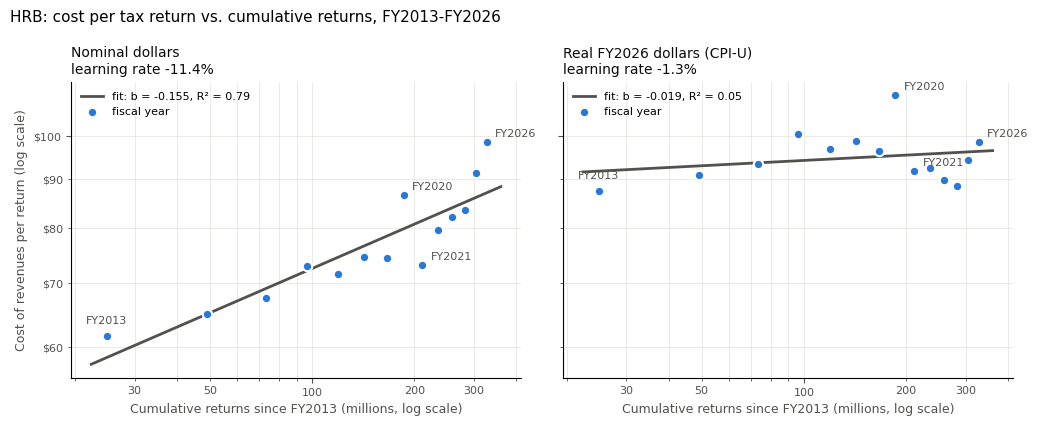

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), sharey=True)
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
xs = np.geomspace(N.min() * 0.9, N.max() * 1.1, 50)
for ax, (key, col, title) in zip(axes, (("nominal", "unit_cost", "Nominal dollars"), ("real", "real_unit_cost", f"Real FY{ROWS[-1]['fy']} dollars (CPI-U)"))):
    f = FIT[key]; y = [r[col] for r in ROWS]
    ax.plot(xs, f["cost1"] * xs ** -f["b"], color=MUTED, lw=2, label=f"fit: b = {f['b']:+.3f}, R² = {f['r2']:.2f}")
    ax.scatter(N, y, s=46, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3, label="fiscal year")
    for i in (0, len(ROWS) - 1) + tuple(i for i, r in enumerate(ROWS) if r["fy"] in (2020, 2021)):
        ax.annotate(f"FY{ROWS[i]['fy']}", (N[i], y[i]), textcoords="offset points", xytext=(0, 9) if i == 0 else (6, 4),
                    ha="center" if i == 0 else "left", fontsize=8, color=MUTED)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{title}\nlearning rate {f['lr']:+.1%}", fontsize=10, color=INK, loc="left")
    ax.set_xlabel(f"Cumulative returns since FY{ROWS[0]['fy']} (millions, log scale)", fontsize=9, color=MUTED)
    ax.grid(True, which="both", color="#e6e6e3", lw=0.6); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.tick_params(which="both", colors=MUTED, labelsize=8); ax.legend(fontsize=8, frameon=False, loc="upper left")
    from matplotlib.ticker import FuncFormatter, LogLocator
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:.0f}")); ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"${v:.0f}" if v in (60, 70, 80, 90, 100, 120) else ""))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}")); ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:.0f}" if v in (30, 50, 100, 200, 300) else ""))
axes[0].set_ylabel("Cost of revenues per return (log scale)", fontsize=9, color=MUTED)
fig.suptitle(f"{TICKER}: cost per tax return vs. cumulative returns, FY{ROWS[0]['fy']}-FY{ROWS[-1]['fy']}", fontsize=11, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(HERE / "lc_loglog.png", dpi=200)
plt.show()

## 6. Direct units vs. proxy, and what accuracy still costs

In [10]:
first, last = ROWS[0], ROWS[-1]
real_chg = last["real_unit_cost"] / first["real_unit_cost"] - 1
nom_chg = last["unit_cost"] / first["unit_cost"] - 1
units_chg = last["units_k"] / first["units_k"] - 1
ACCURACY = [
    ("Direct units, not a proxy.", f"Units are HRB's own count of tax returns prepared (assisted + DIY, worldwide) read from each 10-K, not revenue divided by an assumed price. "
     f"That removes the biggest error in most learning-curve exercises, but the figure is still not a clean 'production unit':"),
    ("The cost line is wider than production.", "Cost of revenues is consolidated: besides tax-professional wages it carries office occupancy, depreciation, bad debt on fees and "
     "Emerald Advance loans, and the costs of financial products (Emerald Card, Spruce) and small-business services (Block Advisors, Wave), whose output is not a tax return. "
     "Marketing and corporate overhead sit in SG&A and are excluded."),
    ("Units mix two very different products.", "An assisted return (a tax professional, an office, roughly $220-$240 of fees in company offices) and a free DIY online return "
     "are each counted as one. A shift toward DIY lowers unit cost with no learning; a shift toward assisted raises it."
     + (f" Here the shift ran toward DIY (U.S. assisted returns {MIX[0]['value']/1e3:.1f}M in FY{MIX[0]['fy']} vs {MIX[-1]['value']/1e3:.1f}M in FY{MIX[-1]['fy']}, "
        "both quoted from the 10-Ks), which should have pushed unit cost down, so mix does not explain the rise." if MIX_OK else "")),
    ("Inflation.", f"Nominal cost per return moved {nom_chg:+.1%} from FY{first['fy']} to FY{last['fy']}; in FY{last['fy']} dollars it moved {real_chg:+.1%}. "
     "CPI-U is a consumer price index, not an index of HRB's inputs (mostly seasonal wages and rent), so the real series is an approximation."),
    ("Definition changes and timing.", "Return counts were restated for several years (e-file acceptance basis, extensions excluded, Free File dropped); COVID pushed part of the 2020 season into FY2021; "
     "the 2021 change of fiscal year leaves a two-month gap; FY2023-FY2026 units are rounded to 0.1 million. The sensitivity checks above show how much each moves b."),
    ("Cumulative volume starts at the window, not at 1955.", f"N counts only returns since FY{first['fy']}. With flat annual volume ({units_chg:+.1%} from first to last year) "
     "the window's cumulative count grows almost linearly, so ln N rises steeply early and flattens late: a fit on it measures how unit cost trended over 14 years, "
     "not HRB's position on a 70-year experience curve. Adding the pre-window history (not published in any filing used here) would compress all 14 points into a small slice of ln N."),
]
for h, t in ACCURACY:
    print(f"* {h} {t}\n")

* Direct units, not a proxy. Units are HRB's own count of tax returns prepared (assisted + DIY, worldwide) read from each 10-K, not revenue divided by an assumed price. That removes the biggest error in most learning-curve exercises, but the figure is still not a clean 'production unit':

* The cost line is wider than production. Cost of revenues is consolidated: besides tax-professional wages it carries office occupancy, depreciation, bad debt on fees and Emerald Advance loans, and the costs of financial products (Emerald Card, Spruce) and small-business services (Block Advisors, Wave), whose output is not a tax return. Marketing and corporate overhead sit in SG&A and are excluded.

* Units mix two very different products. An assisted return (a tax professional, an office, roughly $220-$240 of fees in company offices) and a free DIY online return are each counted as one. A shift toward DIY lowers unit cost with no learning; a shift toward assisted raises it. Here the shift ran toward 

## 7. Interpretation (generated from the numbers above, with fixed thresholds)

In [11]:
fn, fr = FIT["nominal"], FIT["real"]
def strength(r2):
    return "a real curve" if r2 >= 0.8 else ("no curve visible" if r2 < 0.5 else "between the two thresholds (a moderate fit)")
def direction(f):
    return (f"unit cost falls {f['lr']:.1%} per doubling" if f["b"] > 0 else f"unit cost RISES {-f['lr']:.1%} per doubling (a negative learning rate)")
INTERP = [
    f"Nominal fit: {direction(fn)}, R² = {fn['r2']:.2f} over n = {fn['n']} years; inflation-adjusted: {direction(fr)}, R² = {fr['r2']:.2f}. "
    f"By the rule used here (R² above ~0.8 = real curve, below ~0.5 = none visible) the nominal fit is {strength(fn['r2'])} and the real fit is {strength(fr['r2'])}"
    + (", but what the nominal line fits is cost per return rising over time, which is the opposite of a learning curve; once inflation is removed, almost nothing is left to fit."
       if fn["b"] < 0 and fn["r2"] >= 0.5 and fr["r2"] < 0.5 else "."),
    f"For comparison, manufacturing studies typically find learning rates of roughly 10-30% per doubling and labor-heavy services far less; HRB shows no positive rate at all: "
    f"cost per return was ${first['unit_cost']:.2f} in FY{first['fy']} and ${last['unit_cost']:.2f} in FY{last['fy']} ({nom_chg:+.0%} nominal, {real_chg:+.0%} real), "
    f"while annual volume was flat"
    + (" and the mix moved toward cheaper DIY returns" if MIX_OK and MIX[-1]["value"] < MIX[0]["value"] else "")
    + f"; the 95% interval for the real learning rate ({fr['lr_lo']:+.1%} to {fr['lr_hi']:+.1%}) "
    + ("excludes any positive learning." if fr["lr_hi"] < 0 else "does not rule out zero."),
    "The most likely reading is that HRB is a mature firm far out on its curve, where each extra million returns teaches little, so its cost per return follows wages, "
    "rent and its non-tax products rather than accumulated experience.",
    "For a small esthetician-focused bookkeeping and tax firm, this says HRB's scale does not come with a falling cost per return that a newcomer can never catch: "
    "its advantage is brand, office network and software, not a steep experience curve, so a small firm's own learning in its first few hundred clients "
    "(templates, intake, niche deductions) can matter more than the giant's volume.",
]
for s in INTERP:
    print(s, "\n")

Nominal fit: unit cost RISES 11.4% per doubling (a negative learning rate), R² = 0.79 over n = 14 years; inflation-adjusted: unit cost RISES 1.3% per doubling (a negative learning rate), R² = 0.05. By the rule used here (R² above ~0.8 = real curve, below ~0.5 = none visible) the nominal fit is between the two thresholds (a moderate fit) and the real fit is no curve visible, but what the nominal line fits is cost per return rising over time, which is the opposite of a learning curve; once inflation is removed, almost nothing is left to fit. 

For comparison, manufacturing studies typically find learning rates of roughly 10-30% per doubling and labor-heavy services far less; HRB shows no positive rate at all: cost per return was $61.59 in FY2013 and $98.49 in FY2026 (+60% nominal, +13% real), while annual volume was flat and the mix moved toward cheaper DIY returns; the 95% interval for the real learning rate (-4.8% to +2.1%) does not rule out zero. 

The most likely reading is that HRB 

In [12]:
results = dict(ticker=TICKER, company=facts["entityName"], cik=CIK, cost_line=cost_line, built=dt.date.today().isoformat(),
               window=f"FY{ROWS[0]['fy']}-FY{ROWS[-1]['fy']}", rows=ROWS, fit=FIT,
               sensitivity={k: {kk: vv for kk, vv in v.items()} for k, v in SENS.items()},
               units_meta={k: U.get(k) for k in ("unit_name", "selection_rule")}, transition_note=U.get("transition_period", {}).get("note"),
               free_file_note=U.get("free_file", {}).get("note"), unverified_dropped=problems, mix_check=dict(items=MIX, verified=MIX_OK), accuracy=ACCURACY, interpretation=INTERP,
               cpi_base=base_cpi, cpi_gaps=sorted(set(CPI_GAPS)), cpi_source="FRED CPIAUCSL (CPI-U, all items, seasonally adjusted), fiscal-year averages",
               restatement_history={str(k): v for k, v in HISTORY.items() if k >= ROWS[0]["fy"]})
(HERE / "lc_results.json").write_text(json.dumps(results, indent=1, default=float))
print("Wrote lc_results.json and lc_loglog.png")

Wrote lc_results.json and lc_loglog.png
